# Student Performance Analytics and Score Prediction using Machine Learning

**AICTE | IBM SkillsBuild Data Analytics with AI Internship 2026 | BharatCares**  
**Prepared by:** Harsh Pareek

## Project overview
This project demonstrates a complete beginner-friendly data analytics workflow: data validation, exploratory data analysis (EDA), visualisation, supervised machine learning, model evaluation, and responsible interpretation. It explores how study habits and learning-support indicators relate to a simulated final exam score.

> **Data transparency:** The included `student_performance_synthetic.csv` dataset is simulated for learning and reproducibility. It is not collected from real students and should not be treated as evidence about any actual school or learner. The notebook can recreate the same dataset if the CSV file is not present.


## Objectives
1. Inspect the data structure, types, missing values, and distributions.
2. Explore relationships among study habits and the final score.
3. Compare a Linear Regression baseline with a Random Forest model.
4. Explain model metrics and feature importance in plain language.
5. Discuss safe and responsible use of predictions in education.

## Workflow
**Data → Quality checks → EDA → Preprocessing → Model training → Evaluation → Responsible recommendations**


In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

RANDOM_STATE = 42
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)


## 1. Load or create the dataset
The included CSV makes the project easy to run offline. If it is missing, the cell below creates a deterministic sample of 600 simulated records. The formula intentionally includes plausible relationships plus random variation so the workflow can be practised end to end.

In [2]:
def generate_student_data(n=600, seed=42):
    rng = np.random.default_rng(seed)
    study_hours = np.clip(rng.normal(2.8, 1.25, n), 0.25, 8.0)
    attendance = np.clip(rng.beta(8, 2, n) * 100, 35, 100)
    previous_score = np.clip(rng.normal(66, 14, n), 20, 100)
    assignment_rate = np.clip(rng.beta(7, 2, n) * 100, 20, 100)
    sleep_hours = np.clip(rng.normal(7.0, 1.1, n), 3.5, 10.0)
    extracurricular = np.clip(rng.gamma(1.8, 1.0, n), 0, 7)
    internet = rng.choice(["Yes", "No"], size=n, p=[0.88, 0.12])
    parent_support = rng.choice(["Low", "Medium", "High"], size=n, p=[0.2, 0.5, 0.3])
    tutoring = np.clip(rng.poisson(0.8, n), 0, 5)
    support_effect = pd.Series(parent_support).map({"Low": -3.0, "Medium": 0.0, "High": 3.0}).to_numpy()
    internet_effect = (internet == "Yes") * 1.2
    noise = rng.normal(0, 7.0, n)
    score = (35 + 0.35 * previous_score + 2.8 * study_hours
             + 0.25 * (attendance - 70) + 0.15 * (assignment_rate - 70)
             + 1.6 * (sleep_hours - 7) - 0.45 * extracurricular
             + 2.0 * tutoring + support_effect + internet_effect + noise)
    score = np.clip(score, 0, 100).round(1)
    return pd.DataFrame({
        "student_id": [f"S{i:04d}" for i in range(1, n + 1)],
        "study_hours_per_day": study_hours.round(2),
        "attendance_rate": attendance.round(1),
        "previous_score": previous_score.round(1),
        "assignment_completion_rate": assignment_rate.round(1),
        "sleep_hours": sleep_hours.round(1),
        "extracurricular_hours_per_day": extracurricular.round(2),
        "internet_access": internet,
        "parent_support": parent_support,
        "tutoring_sessions_per_month": tutoring,
        "final_score": score,
    })

csv_file = Path("student_performance_synthetic.csv")
if csv_file.exists():
    df = pd.read_csv(csv_file)
    print(f"Loaded included dataset: {csv_file.resolve()}")
else:
    df = generate_student_data()
    df.to_csv(csv_file, index=False)
    print(f"CSV not found. Created reproducible synthetic data at: {csv_file.resolve()}")

print(f"Rows: {df.shape[0]:,} | Columns: {df.shape[1]}")
df.head()


Loaded included dataset: /mnt/data/harsh_student_analytics/student_performance_synthetic.csv
Rows: 600 | Columns: 11


,student_id,study_hours_per_day,attendance_rate,previous_score,assignment_completion_rate,sleep_hours,extracurricular_hours_per_day,internet_access,parent_support,tutoring_sessions_per_month,final_score
0,S0001,3.18,70.1,67.7,75.0,8.0,2.39,Yes,Medium,2,74.2
1,S0002,1.50,67.9,79.8,90.9,7.7,2.52,Yes,Low,1,64.1
2,S0003,3.74,85.5,58.1,86.0,3.7,1.30,Yes,High,0,61.7
3,S0004,3.98,84.1,57.2,62.4,7.6,2.36,Yes,High,1,69.0
4,S0005,0.36,90.8,80.8,63.5,5.9,1.39,Yes,Medium,4,78.1


### Dataset dictionary

| Column | Meaning |
|---|---|
| `student_id` | Synthetic row identifier (not used for training) |
| `study_hours_per_day` | Daily study time in hours |
| `attendance_rate` | Attendance percentage |
| `previous_score` | Previous assessment score (0-100) |
| `assignment_completion_rate` | Assignment completion percentage |
| `sleep_hours` | Average sleep hours per day |
| `extracurricular_hours_per_day` | Daily extracurricular time |
| `internet_access` | Simulated Yes/No indicator |
| `parent_support` | Simulated Low/Medium/High support category |
| `tutoring_sessions_per_month` | Number of tutoring sessions in a month |
| `final_score` | Simulated final score to be predicted (0-100) |


## 2. Data quality checks
Check data types, duplicate records, missing values, and the range of the target column before analysis.

In [3]:
print("Data types and non-null counts:")
df.info()
print("\nMissing values by column:")
display(df.isna().sum().to_frame("missing_values"))
print("Duplicate full rows:", int(df.duplicated().sum()))
print("\nNumeric summary:")
display(df.describe().round(2))
assert df["final_score"].between(0, 100).all(), "Target score is outside the expected range."


Data types and non-null counts:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 11 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   student_id                     600 non-null    object 
 1   study_hours_per_day            600 non-null    float64
 2   attendance_rate                600 non-null    float64
 3   previous_score                 600 non-null    float64
 4   assignment_completion_rate     600 non-null    float64
 5   sleep_hours                    600 non-null    float64
 6   extracurricular_hours_per_day  600 non-null    float64
 7   internet_access                600 non-null    object 
 8   parent_support                 600 non-null    object 
 9   tutoring_sessions_per_month    600 non-null    int64  
 10  final_score                    600 non-null    float64
dtypes: float64(7), int64(1), object(3)
memory usage: 51.7+ KB

Missing values by c

,missing_values
student_id,0
study_hours_per_day,0
attendance_rate,0
previous_score,0
assignment_completion_rate,0
sleep_hours,0
extracurricular_hours_per_day,0
internet_access,0
parent_support,0
tutoring_sessions_per_month,0


Duplicate full rows: 0

Numeric summary:


,study_hours_per_day,attendance_rate,previous_score,assignment_completion_rate,sleep_hours,extracurricular_hours_per_day,tutoring_sessions_per_month,final_score
count,600.00,600.00,600.00,600.00,600.00,600.00,600.00,600.00
mean,2.77,79.71,66.47,77.97,7.04,1.76,0.79,71.64
std,1.20,12.66,13.34,12.92,1.13,1.28,0.91,10.50
min,0.25,35.10,27.50,32.80,3.70,0.02,0.00,35.40
25%,1.93,72.10,56.98,69.68,6.30,0.86,0.00,65.20
50%,2.78,81.80,66.85,79.70,7.00,1.39,1.00,71.30
75%,3.53,89.43,75.90,88.00,7.82,2.39,1.00,78.22
max,6.44,99.20,100.00,99.80,10.00,7.00,5.00,100.00


## 3. Exploratory Data Analysis (EDA)
Visualisations help identify distributions and possible relationships. Relationships in this simulated dataset are illustrative, not causal evidence.

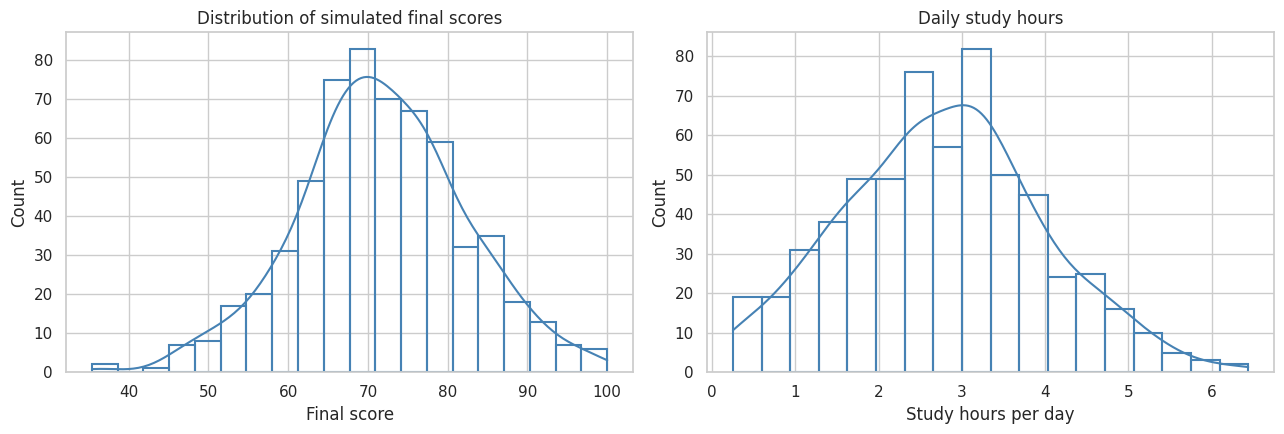

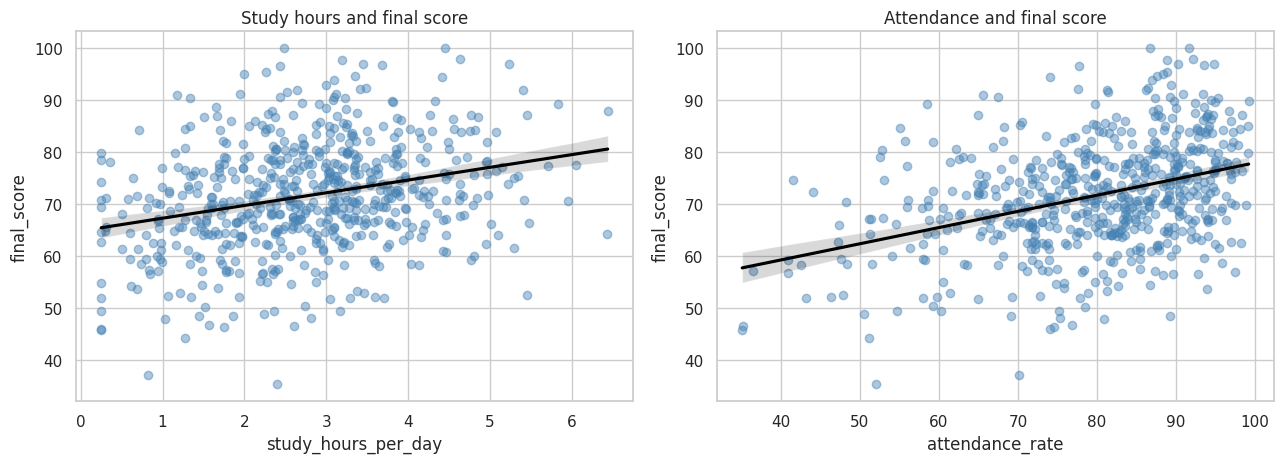

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
sns.histplot(data=df, x="final_score", bins=20, kde=True, fill=False, color="steelblue", ax=axes[0])
axes[0].set_title("Distribution of simulated final scores")
axes[0].set_xlabel("Final score")
sns.histplot(data=df, x="study_hours_per_day", bins=18, kde=True, fill=False, color="steelblue", ax=axes[1])
axes[1].set_title("Daily study hours")
axes[1].set_xlabel("Study hours per day")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
sns.regplot(data=df, x="study_hours_per_day", y="final_score", scatter_kws={"alpha": 0.45, "color": "steelblue"}, line_kws={"color": "black"}, ax=axes[0])
axes[0].set_title("Study hours and final score")
sns.regplot(data=df, x="attendance_rate", y="final_score", scatter_kws={"alpha": 0.45, "color": "steelblue"}, line_kws={"color": "black"}, ax=axes[1])
axes[1].set_title("Attendance and final score")
plt.tight_layout()
plt.show()


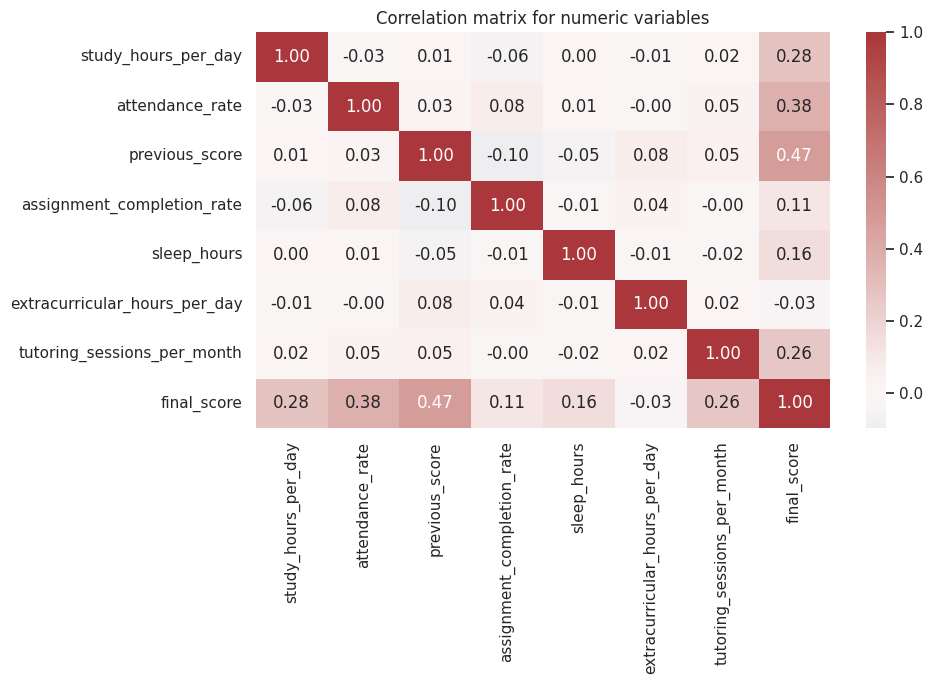

,count,mean,median
attendance_band,,,
≤60%,51,63.49,64.3
61–75%,139,68.37,68.3
76–90%,276,72.37,71.7
>90%,134,76.65,76.5


In [5]:
corr_cols = ["study_hours_per_day", "attendance_rate", "previous_score",
             "assignment_completion_rate", "sleep_hours",
             "extracurricular_hours_per_day", "tutoring_sessions_per_month", "final_score"]
plt.figure(figsize=(10, 7))
sns.heatmap(df[corr_cols].corr(), annot=True, fmt=".2f", cmap="vlag", center=0)
plt.title("Correlation matrix for numeric variables")
plt.tight_layout()
plt.show()

# Show average scores by attendance band to make grouped analysis easy to interpret.
df["attendance_band"] = pd.cut(df["attendance_rate"], bins=[0, 60, 75, 90, 101], labels=["≤60%", "61–75%", "76–90%", ">90%"], right=True)
attendance_summary = df.groupby("attendance_band", observed=False)["final_score"].agg(["count", "mean", "median"]).round(2)
display(attendance_summary)


## 4. Prepare the data and train predictive models
The student identifier is excluded because it has no learning meaning. Numeric columns are scaled and categorical columns are one-hot encoded inside a `Pipeline`, preventing preprocessing from being fitted on the test data. An 80/20 train-test split is used with a fixed seed for reproducibility.

In [6]:
# Exclude the identifier and target from model inputs.
feature_columns = [c for c in df.columns if c not in ["student_id", "final_score", "attendance_band"]]
X = df[feature_columns].copy()
y = df["final_score"].copy()

categorical_columns = X.select_dtypes(include=["object"]).columns.tolist()
numeric_columns = [c for c in X.columns if c not in categorical_columns]
preprocessor = ColumnTransformer(transformers=[
    ("numeric", StandardScaler(), numeric_columns),
    ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_columns),
])
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE
)

models = {
    "Linear Regression": Pipeline([
        ("preprocessor", preprocessor),
        ("model", LinearRegression()),
    ]),
    "Random Forest": Pipeline([
        ("preprocessor", preprocessor),
        ("model", RandomForestRegressor(
            n_estimators=250, max_depth=8, min_samples_leaf=3,
            random_state=RANDOM_STATE, n_jobs=-1
        )),
    ]),
}
print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")
print("Numeric features:", numeric_columns)
print("Categorical features:", categorical_columns)


Training rows: 480 | Test rows: 120
Numeric features: ['study_hours_per_day', 'attendance_rate', 'previous_score', 'assignment_completion_rate', 'sleep_hours', 'extracurricular_hours_per_day', 'tutoring_sessions_per_month']
Categorical features: ['internet_access', 'parent_support']


## 5. Evaluate model performance

- **MAE** (Mean Absolute Error): average absolute prediction error, in score points; lower is better.
- **RMSE** (Root Mean Squared Error): penalises larger errors more strongly; lower is better.
- **R²**: proportion of target variation explained on this test split; closer to 1 is better, while negative values indicate performance worse than a mean baseline.

These metrics describe this simulated dataset only.

In [7]:
results = []
for model_name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)
    results.append({
        "Model": model_name,
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": mean_squared_error(y_test, predictions) ** 0.5,
        "R²": r2_score(y_test, predictions),
    })

metrics_df = pd.DataFrame(results).sort_values("RMSE").reset_index(drop=True)
display(metrics_df.round(3))
best_model_name = metrics_df.loc[0, "Model"]
best_model = models[best_model_name]
best_predictions = best_model.predict(X_test)
print(f"Model with the lowest test RMSE in this run: {best_model_name}")


,Model,MAE,RMSE,R²
0,Linear Regression,5.659,6.853,0.575
1,Random Forest,6.425,7.957,0.427


Model with the lowest test RMSE in this run: Linear Regression


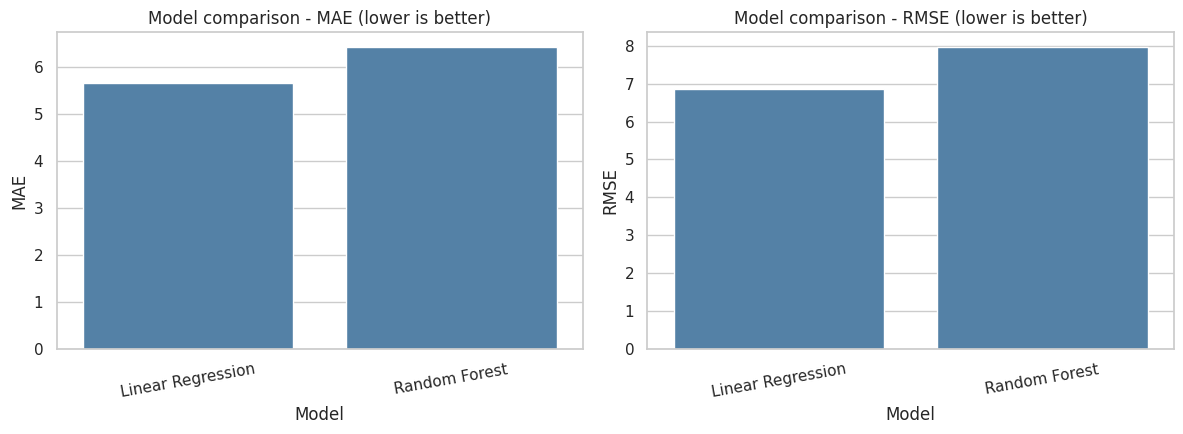

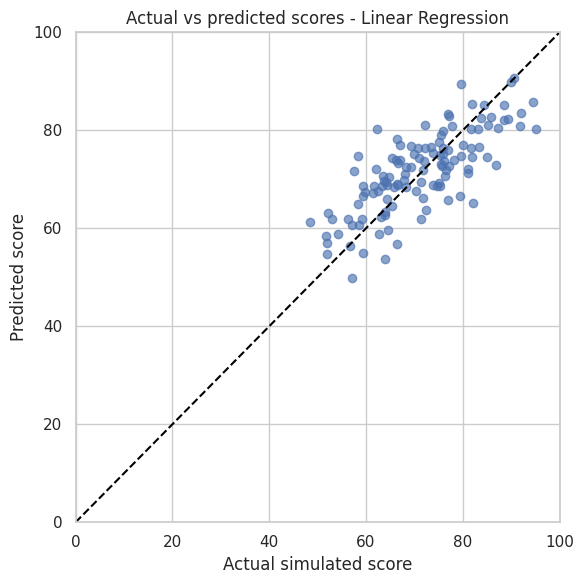

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
sns.barplot(data=metrics_df, x="Model", y="MAE", color="steelblue", ax=axes[0])
axes[0].set_title("Model comparison - MAE (lower is better)")
axes[0].tick_params(axis="x", rotation=10)
sns.barplot(data=metrics_df, x="Model", y="RMSE", color="steelblue", ax=axes[1])
axes[1].set_title("Model comparison - RMSE (lower is better)")
axes[1].tick_params(axis="x", rotation=10)
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 6))
plt.scatter(y_test, best_predictions, alpha=0.65)
plt.plot([0, 100], [0, 100], linestyle="--", color="black")
plt.xlim(0, 100)
plt.ylim(0, 100)
plt.xlabel("Actual simulated score")
plt.ylabel("Predicted score")
plt.title(f"Actual vs predicted scores - {best_model_name}")
plt.tight_layout()
plt.show()


## 6. Understand model feature importance
Random Forest feature importance shows which inputs the fitted model used most for reducing prediction error. It is not proof that a feature causes a score to change. One-hot encoded categories appear as separate features.

,Feature,Importance
2,numeric__previous_score,0.3410
1,numeric__attendance_rate,0.2351
0,numeric__study_hours_per_day,0.1597
3,numeric__assignment_completion_rate,0.0727
4,numeric__sleep_hours,0.0673
5,numeric__extracurricular_hours_per_day,0.0514
6,numeric__tutoring_sessions_per_month,0.0423
9,categorical__parent_support_High,0.0128
10,categorical__parent_support_Low,0.0080
11,categorical__parent_support_Medium,0.0046


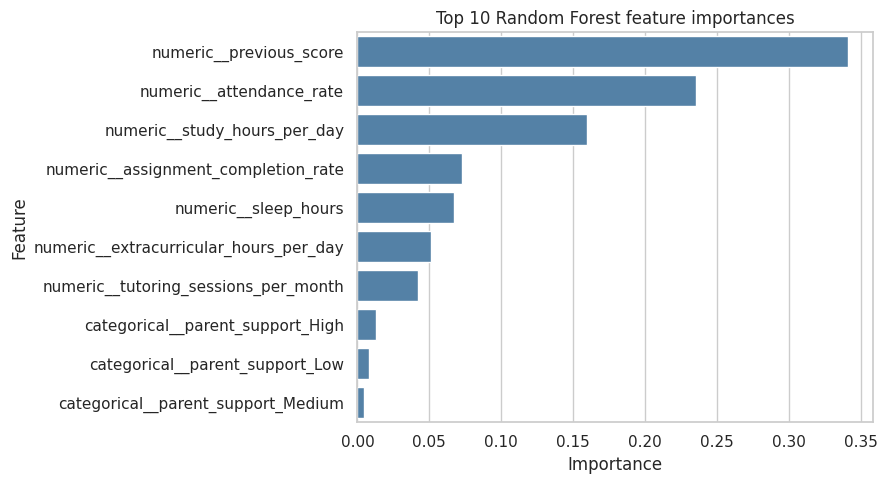

In [9]:
rf_pipeline = models["Random Forest"]
rf_preprocessor = rf_pipeline.named_steps["preprocessor"]
rf_model = rf_pipeline.named_steps["model"]
feature_names = rf_preprocessor.get_feature_names_out()
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": rf_model.feature_importances_,
}).sort_values("Importance", ascending=False)
display(feature_importance.head(10).round(4))

plt.figure(figsize=(9, 5))
sns.barplot(data=feature_importance.head(10), x="Importance", y="Feature", color="steelblue")
plt.title("Top 10 Random Forest feature importances")
plt.tight_layout()
plt.show()


## 7. Responsible interpretation and recommendations

1. Use analytics to identify patterns for further review, not to label students as failures or successes.
2. If a real school used a model, staff should validate it on representative, consented data and check performance across student groups before deployment.
3. Keep private student data secure, collect only what is necessary, and explain how predictions are used.
4. Predictions must not be used alone for admissions, grading, discipline, or access to support.
5. The simulated data was generated from a known formula, so the model's results are a learning demonstration rather than a real-world educational finding.

### Limitations and future work
The sample is synthetic and may not reflect real student populations. The model comparison uses a single random split and limited tuning. Future work could use a properly licensed, anonymised real dataset, cross-validation, fairness checks, uncertainty intervals, and a simple dashboard for educators.

In [10]:
# Save reusable outputs so the results can be included in a portfolio.
metrics_df.to_csv("model_metrics.csv", index=False)
feature_importance.to_csv("feature_importance.csv", index=False)
print("Saved model_metrics.csv and feature_importance.csv in the project folder.")
print("Project completed successfully.")


Saved model_metrics.csv and feature_importance.csv in the project folder.
Project completed successfully.


## References

- Included dataset: `student_performance_synthetic.csv` (simulated for this project; no real student records).
- Public real-world benchmark for future exploration: [UCI Student Performance dataset](https://archive.ics.uci.edu/dataset/320/student+performance). This notebook does **not** claim to analyse the UCI records; they are listed as an optional next step only.
- Tools: Python, pandas, NumPy, Matplotlib, Seaborn, and scikit-learn.
